# Learn BayMorph

Fit a galaxy with BayMorph through its recommended configuration-driven workflow.

> **Estimated time:** 15–20 minutes  
> **Prerequisites:** BayMorph installed in the current environment  
> **Expected outputs:** a prepared image, PSF, posterior samples, best-fit model, residual diagnostics, and a reproducible output directory

This tutorial uses a synthetic single-Sérsic galaxy so that the complete workflow can be reproduced without external data.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np

from baymorph import BayMorphRunner
from baymorph.pipeline import run_simulation_from_config
from baymorph.plotting import plot_log_data_model_residual

if Path.cwd().name == "notebooks":
    os.chdir("..")

CONFIG_PATH = Path("configs/learn_baymorph.yaml")

## Prepare the tutorial dataset

The configuration describes both the synthetic observation and the analysis. The following cell creates the input FITS image when it is not already available.

> **Note**  
> For an observed galaxy, replace the configuration path with your own YAML file. The BayMorph workflow itself does not change.

In [2]:
tutorial_image = Path(
    "runs/learn_baymorph/input/learn_baymorph.fits"
)

if not tutorial_image.exists():
    run_simulation_from_config(CONFIG_PATH)

print(f"Configuration: {CONFIG_PATH}")
print(f"Input image:   {tutorial_image}")

Configuration: configs/learn_baymorph.yaml
Input image:   runs/learn_baymorph/input/learn_baymorph.fits


## The recommended workflow

Most BayMorph analyses need only a runner and a single execution command. Image preparation, PSF handling, Bayesian fitting, and diagnostics are coordinated from the YAML configuration.

In [3]:
runner = BayMorphRunner(
    "configs/learn_baymorph.yaml"
)

In [4]:
results = runner.run(
    diagnostics=True,
)

✓ Image preparation completed

────────────────────────────────────────────────────
Running Dynesty fit: single_sersic
ndim=8, nlive=50, sample=rwalk, bound=multi
────────────────────────────────────────────────────


────────────────────────────────────────────────────
Completed Dynesty fit: single_sersic
logZ=-28881.1
logZerr=2.72281
ncall=36917
────────────────────────────────────────────────────
✓ Bayesian fitting completed
✓ Corner plots generated
✓ Residual maps generated
✓ Radial profiles generated
✓ All diagnostics generated


## What BayMorph produced

The runner has prepared the target image, applied the configured Gaussian PSF, sampled the posterior, selected the best-fit model, and generated the configured diagnostics.

> **Tip**  
> Intermediate products remain available on the runner, so the analysis can be inspected without repeating any stage.

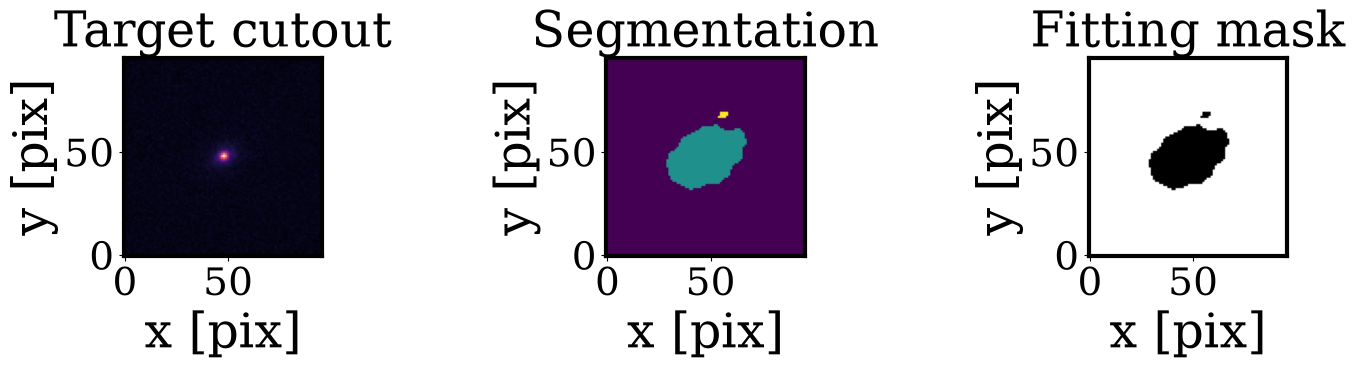

Cutout mode:       fixed
Cutout shape:      (96, 96)
Background level:  20.1138
Target position:   (48, 48)


In [5]:
image = runner.image

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

panels = (
    (image.cutout, "Target cutout", "magma"),
    (image.segmentation, "Segmentation", "viridis"),
    (image.automatic_mask, "Fitting mask", "gray_r"),
)

for ax, (panel, title, cmap) in zip(axes, panels):
    ax.imshow(panel, origin="lower", cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")

plt.tight_layout()
plt.show()

print(f"Cutout mode:       {image.cutout_mode}")
print(f"Cutout shape:      {image.cutout.shape}")
print(f"Background level:  {image.background:.6g}")
print(f"Target position:   ({image.target_x}, {image.target_y})")

## Inspect the fit

A single-model analysis returns a `RealFitProducts` object. It contains the posterior, maximum-likelihood parameters, rendered model, residual maps, and goodness-of-fit statistics.

In [6]:
fit = results
posterior = fit.posterior

print(f"Model:          {fit.model_name}")
print(f"log(Z):         {posterior.logz[-1]:.4f}")
print(f"Reduced chi^2:  {fit.reduced_chi2:.4f}")
print()
print("Posterior summaries")
print("-" * 66)
print(f"{'Parameter':<16}{'Median':>14}{'16th percentile':>18}{'84th percentile':>18}")

for name in posterior.parameter_names:
    summary = posterior.summary(name)
    print(
        f"{name:<16}"
        f"{summary['median']:>14.5g}"
        f"{summary['q16']:>18.5g}"
        f"{summary['q84']:>18.5g}"
    )

Model:          single_sersic
log(Z):         -28881.1457
Reduced chi^2:  1.0534

Posterior summaries
------------------------------------------------------------------
Parameter               Median   16th percentile   84th percentile
flux                     22414             21915             22920
re                       10.34             9.505              10.9
n                       3.9837            3.6075            4.0618
q                      0.71105            0.6987           0.72148
theta                  0.49998           0.48496           0.51732
x0                      47.964            47.944            47.975
y0                      48.081            48.058            48.092
sky                   -0.42294          -0.49703          -0.36155


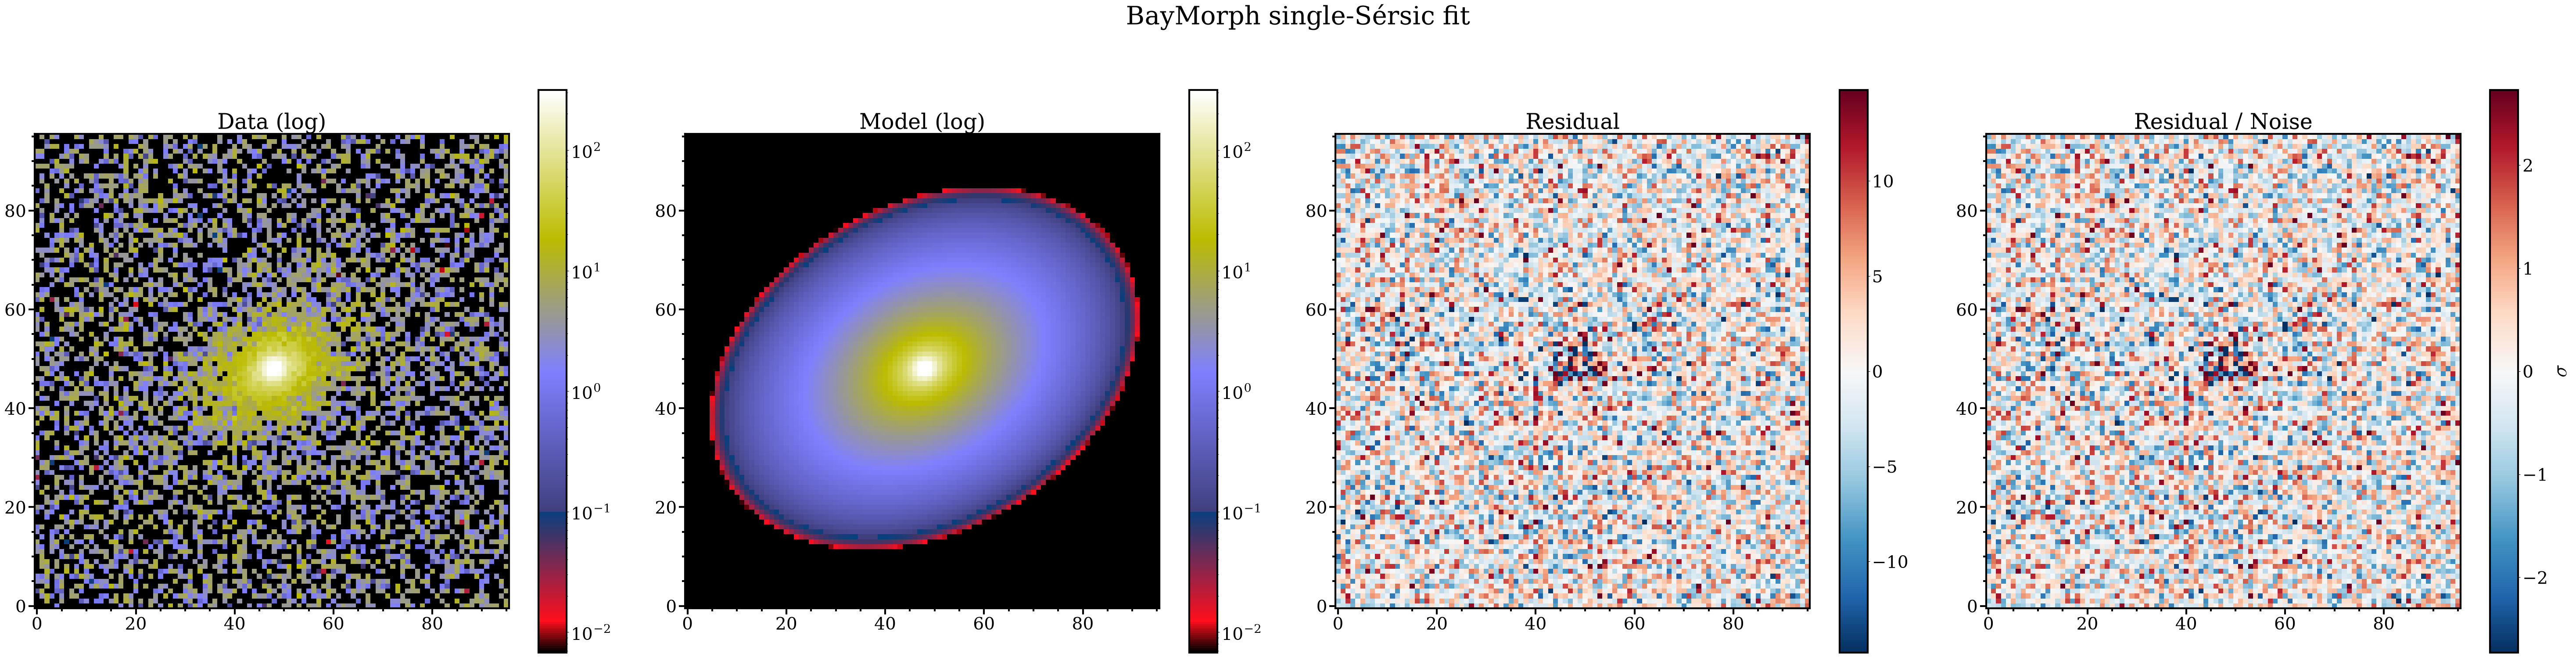

In [7]:
fig, axes = plot_log_data_model_residual(
    image.prepared_data,
    fit.best_model_image,
    noise=fit.noise,
    title="BayMorph single-Sérsic fit",
)
plt.show()

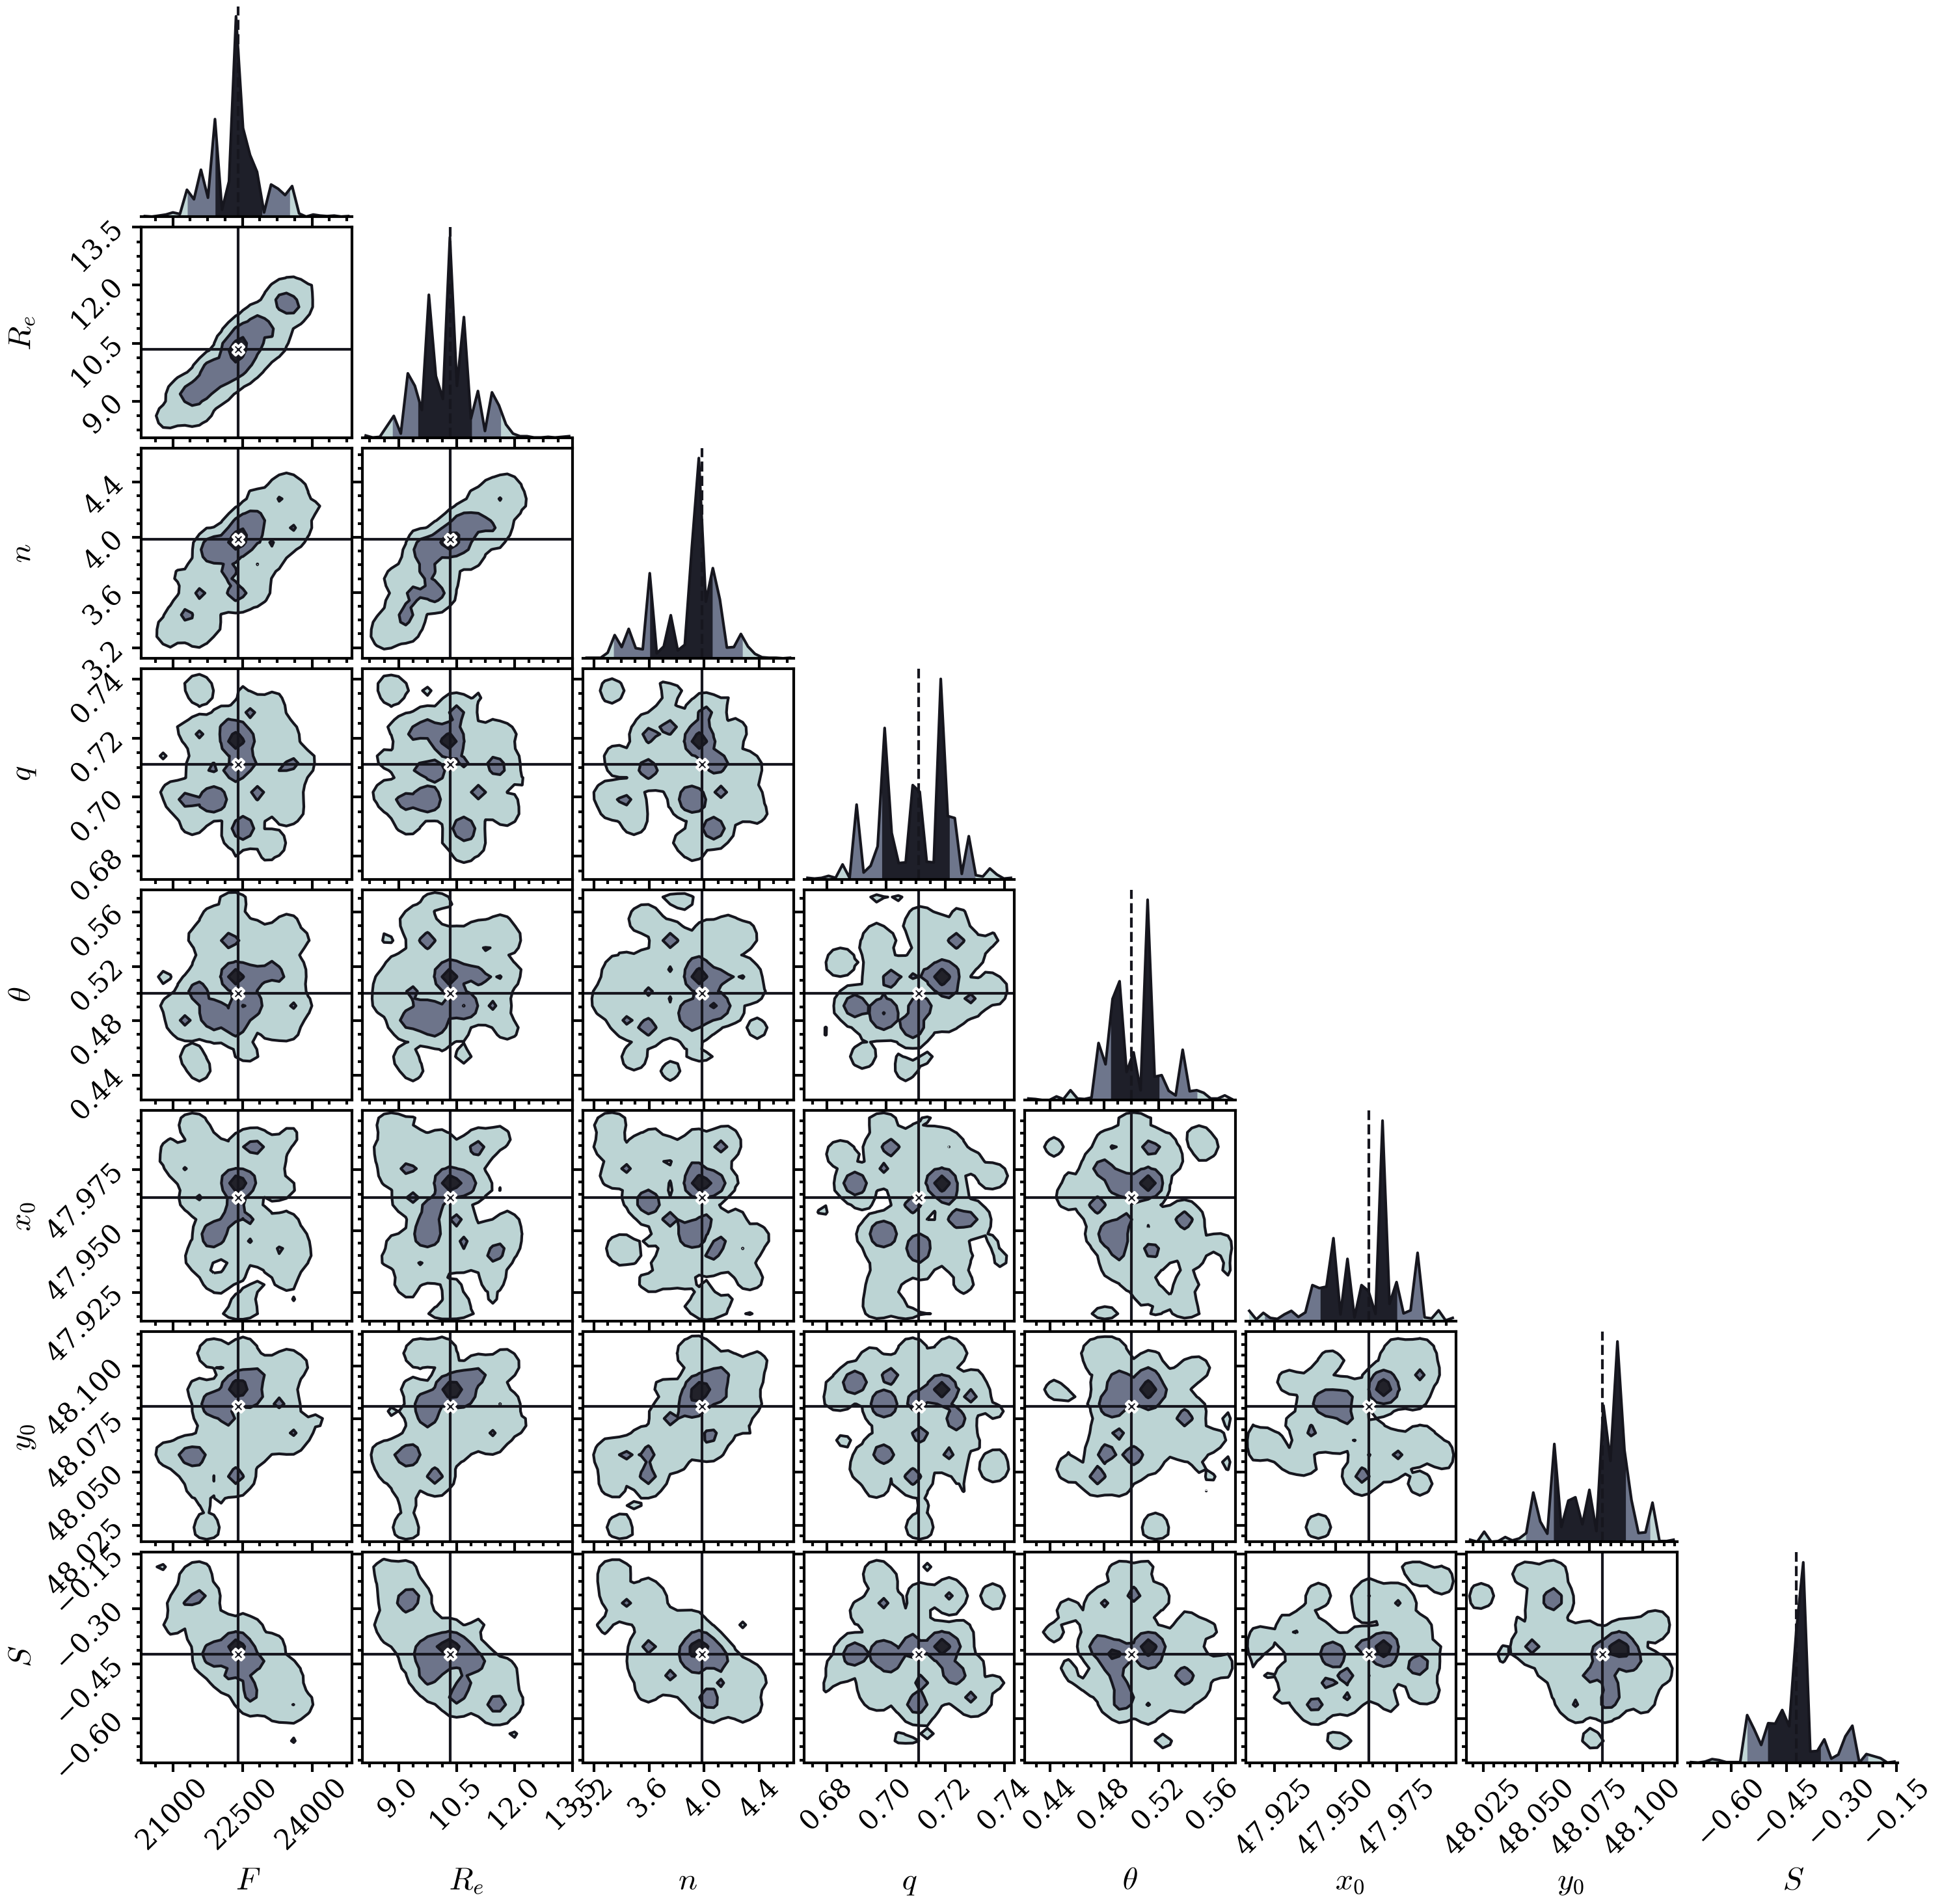

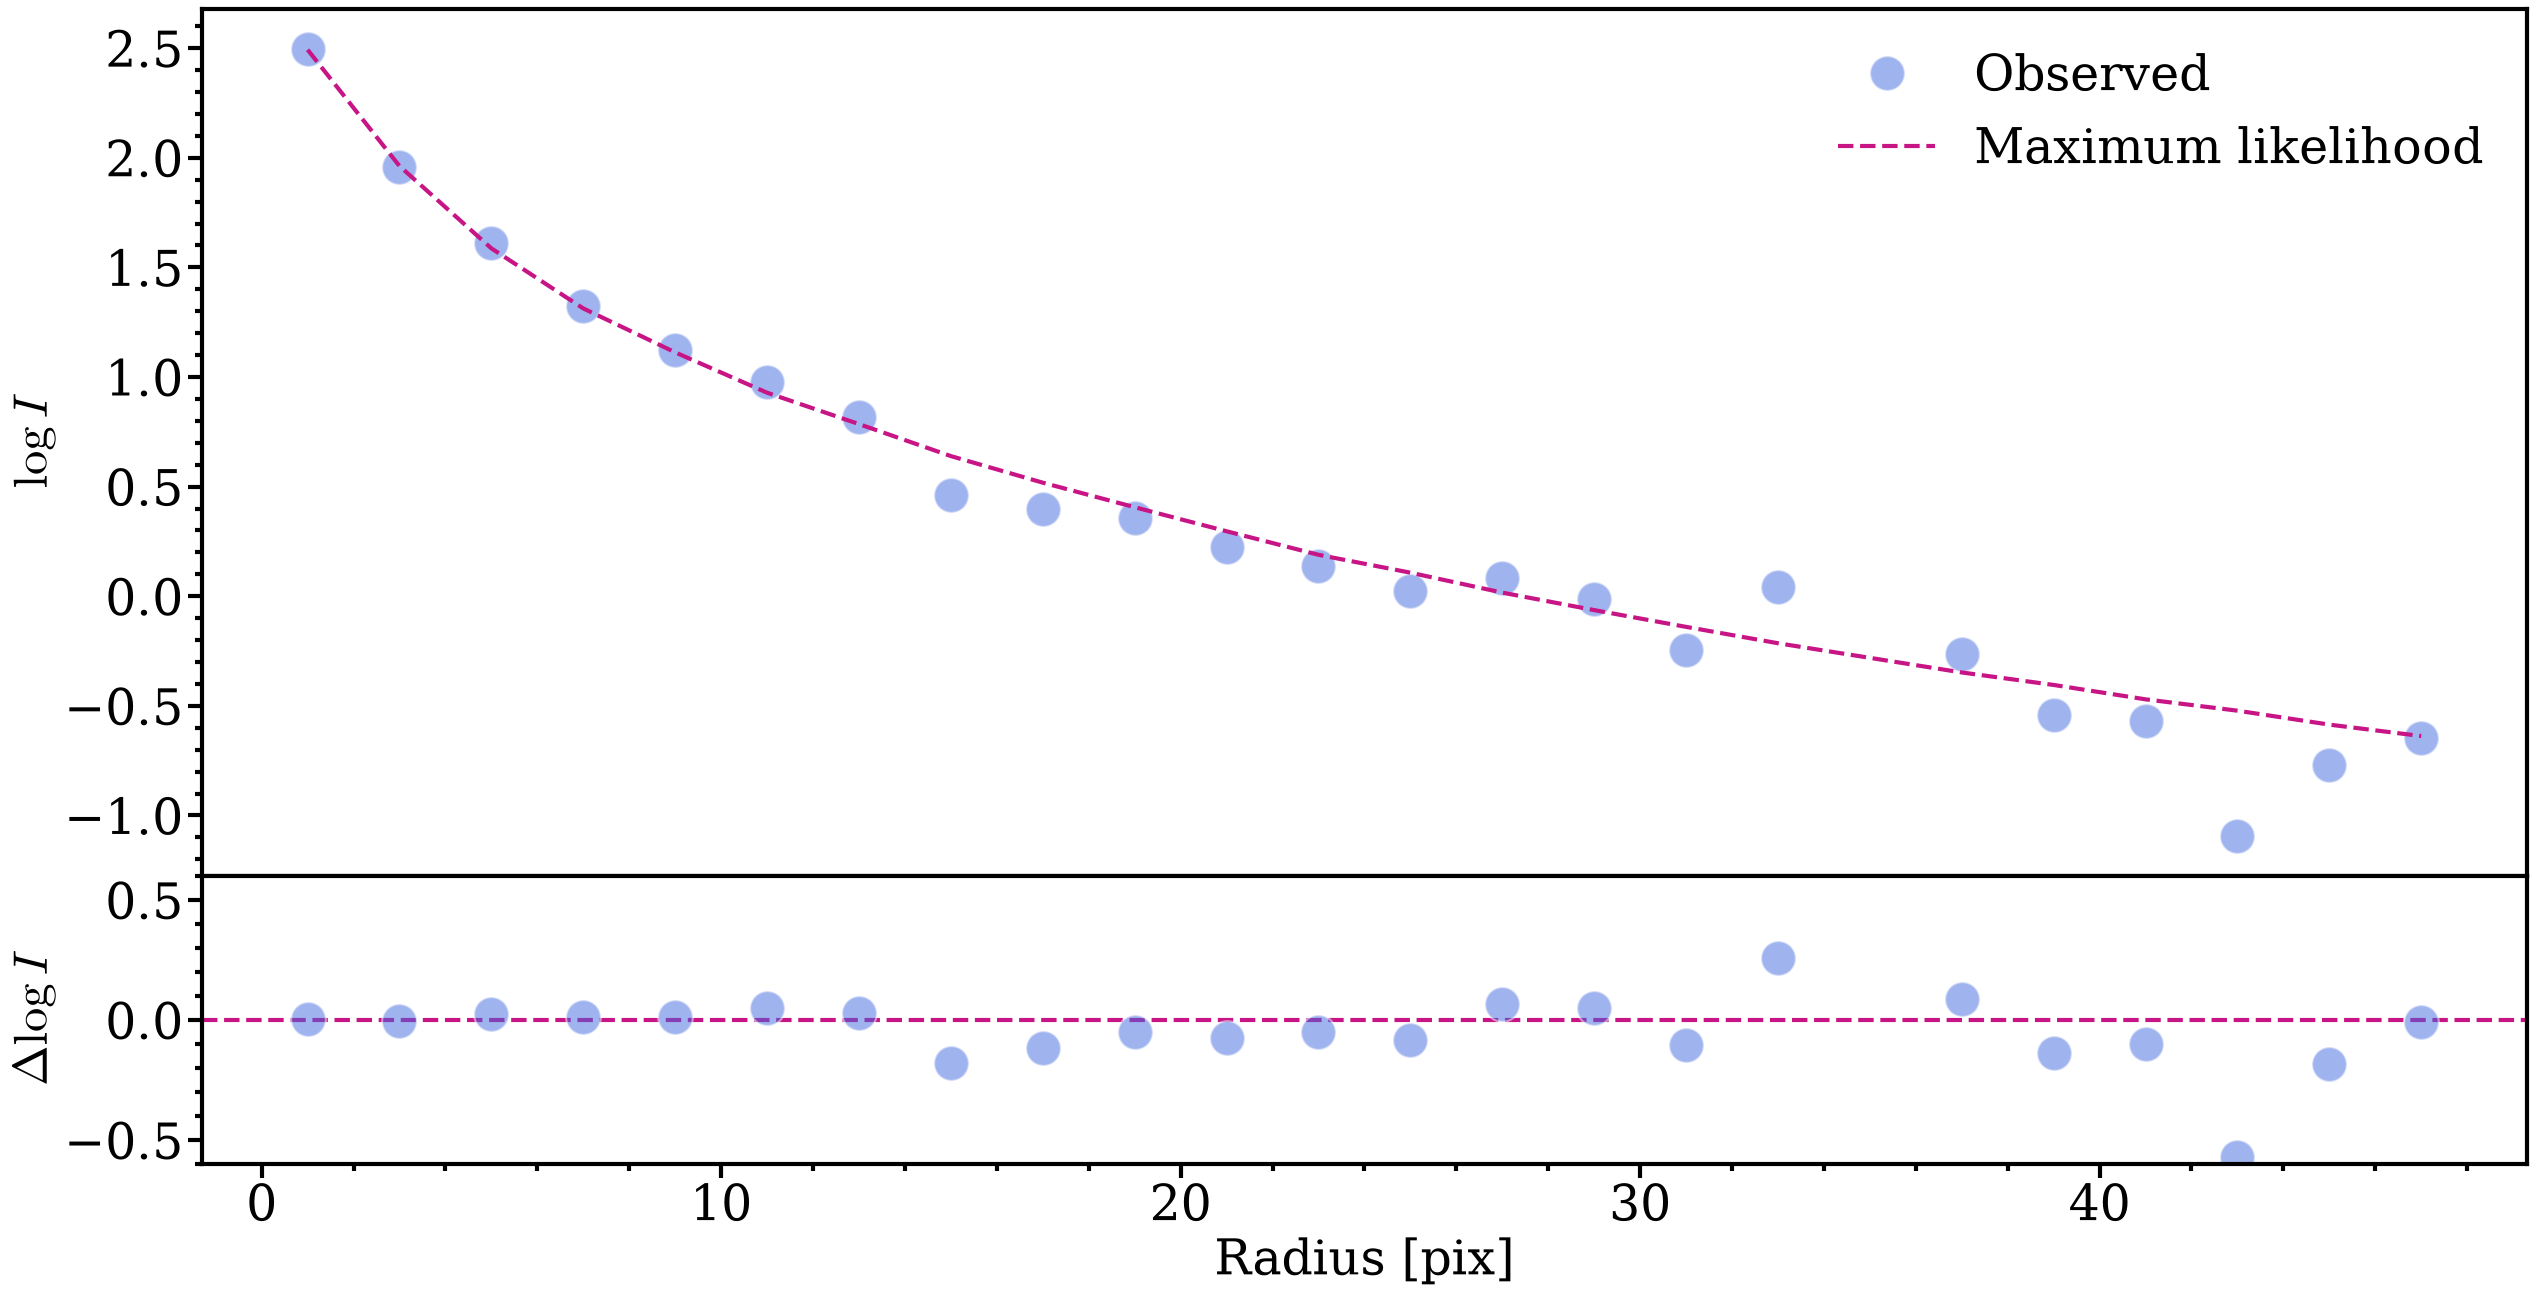

In [8]:
corner_figure, _, _ = fit.corner()
plt.show()

profile_figure, _ = fit.radial_profile()
plt.show()

## Reproducible outputs

BayMorph stores the resolved configuration, prepared data, PSF products, fit summaries, posterior diagnostics, and model-comparison products in a target-specific directory.

In [9]:
output_directory = runner.output_dir / runner.config["object"]["name"]

print(output_directory)

for path in sorted(output_directory.rglob("*")):
    relative = path.relative_to(output_directory)
    depth = len(relative.parts) - 1
    marker = "/" if path.is_dir() else ""
    print(f"{'    ' * depth}├── {relative.name}{marker}")

runs/learn_baymorph
├── config_resolved.yaml
├── fits/
    ├── single_sersic/
        ├── best_model_image.npy
        ├── best_parameters.json
        ├── corner.png
        ├── data_model_residual.png
        ├── fit_summary.json
        ├── fit_summary.txt
        ├── norm_residual.npy
        ├── radial_profile.png
        ├── residual.npy
├── image_preparation/
    ├── automatic_mask.npy
    ├── image_preparation_metadata.json
    ├── large_cutout.npy
    ├── mask.fits
    ├── noise_map.fits
    ├── original_image.npy
    ├── prepared_image.fits
    ├── radial_profile.npz
    ├── segmentation.npy
    ├── sky_region.npz
    ├── target_segment.npy
├── input/
    ├── learn_baymorph.fits
├── model_comparison/
├── psf/
    ├── diagnostics/
        ├── empirical_psf_diagnostic.pdf
    ├── psf.fits
    ├── psf_metadata.json
├── truth/
    ├── truth.json


## Advanced workflow

Most users should keep using `runner.run()`. The explicit stages are available when an analysis requires inspection or intervention between steps.

```python
runner = BayMorphRunner("configs/real_galaxy.yaml")

runner.prepare_image()
runner.select_psf_candidates()
runner.build_psf()
runner.fit()
runner.diagnostics()
```

A Gaussian PSF, as used in this tutorial, does not require candidate selection or empirical construction.

---

## Next notebook

Continue with **Notebook 2 — Understand BayMorph** to examine observations, models, priors, likelihoods, samplers, and the scientific choices encoded by the configuration.